# Week 9 Homework

***Due (pushed to your GitHub branch) on 11/13 by 11:59 pm***

## Count QC

Use Python to filter your counts:

1. Remove any gene that has a total expression count (across all samples) of < 10.
2. Remove any gene that was expressed in <= 6 samples.

In [8]:
# import needed libraries
import os
import pickle as pkl

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

import pandas as pd
import numpy as np

from sklearn.metrics import pairwise_distances

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from sklearn.preprocessing import StandardScaler

In [2]:
# display data from star_counts_axolotl
counts_df = pd.read_csv("/data/users/carltoga2473/BIOL343/8_counting/star_counts_axolotl.tsv", sep="\t", header=1)
counts_df.iloc[:, 6:32] = counts_df.iloc[:, 6:32].astype('int')
counts_df

,Geneid,Chr,Start,End,Strand,Length,/data/users/carltoga2473/BIOL343/8_counting/star.bam:DMSO_1a,/data/users/carltoga2473/BIOL343/8_counting/star.bam:DMSO_1b,/data/users/carltoga2473/BIOL343/8_counting/star.bam:DMSO_1c,/data/users/carltoga2473/BIOL343/8_counting/star.bam:DMSO_1d,/data/users/carltoga2473/BIOL343/8_counting/star.bam:DMSO_1e,/data/users/carltoga2473/BIOL343/8_counting/star.bam:DMSO_1f,/data/users/carltoga2473/BIOL343/8_counting/star.bam:AM580_2a,/data/users/carltoga2473/BIOL343/8_counting/star.bam:AM580_2b,/data/users/carltoga2473/BIOL343/8_counting/star.bam:AM580_2c,/data/users/carltoga2473/BIOL343/8_counting/star.bam:AM580_2d,/data/users/carltoga2473/BIOL343/8_counting/star.bam:AM580_2e,/data/users/carltoga2473/BIOL343/8_counting/star.bam:AM580_2f
0,AMEX60DD000001,chr10p;chr10p;chr10p;chr10p,313039;313800;314856;315024,314183;313931;315023;315424,+;+;+;+,1714,0.0,2.0,0.0,0.0,2.0,1.0,0.0,0.0,0.0,2.0,0.0,6.0
1,AMEX60DD000002,chr10p;chr10p,313679;358361,316338;358550,-;-,2850,35.0,50.0,41.0,70.0,51.0,49.0,46.0,78.0,61.0,86.0,87.0,54.0
2,AMEX60DD000003,chr10p;chr10p;chr10p;chr10p,489232;508794;508795;510337,489386;510169;514890;514890,+;+;+;+,6252,387.0,369.0,530.0,596.0,551.0,413.0,359.0,518.0,627.0,556.0,695.0,645.0
3,AMEX60DD000004,chr10p;chr10p,697815;769665,702473;769805,-;-,4800,100.0,106.0,104.0,134.0,136.0,80.0,86.0,144.0,142.0,170.0,180.0,136.0
4,AMEX60DD000005,chr10p;chr10p;chr10p;chr10p;chr10p;chr10p;chr1...,770040;770040;801485;801485;877425;915118;9151...,770424;770414;801606;801606;877977;915167;9151...,+;+;+;+;+;+;+;+;+,1487,63.0,71.0,99.0,107.0,104.0,55.0,63.0,126.0,109.0,108.0,143.0,116.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99083,AMEX60DDU001042272,C0217363,39999,40387,-,389,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99084,AMEX60DDU001042273,C0217363,40647,40867,-,221,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99085,AMEX60DDU001042274,C0217365,3951,4179,-,229,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99086,AMEX60DDU001042275,C0217365,6394,6774,-,381,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# display only column Geneid and count columns
star_cols = [c for c in counts_df.columns if "star.bam" in c]
counts_subset = counts_df[["Geneid"] + star_cols].copy()

# rename count columns to each group's specific sample name (DMSO and Am580)
prefix = "/data/users/carltoga2473/BIOL343/8_counting/star.bam:"
def strip_prefix(name: str) -> str:
    return name.replace(prefix, "")
counts_subset.rename(columns={c: strip_prefix(c) for c in star_cols}, inplace=True)

# compute total_counts across numeric sample columns (row-wise)
# treat NA as 0, matching na.rm = TRUE
sample_cols = [c for c in counts_subset.columns if c != "Geneid"]
counts_numeric = counts_subset[sample_cols].apply(
    pd.to_numeric, errors="coerce").fillna(0)
counts_subset["total_counts"] = counts_numeric.sum(axis=1)

counts_subset

,Geneid,DMSO_1a,DMSO_1b,DMSO_1c,DMSO_1d,DMSO_1e,DMSO_1f,AM580_2a,AM580_2b,AM580_2c,AM580_2d,AM580_2e,AM580_2f,total_counts
0,AMEX60DD000001,0.0,2.0,0.0,0.0,2.0,1.0,0.0,0.0,0.0,2.0,0.0,6.0,13.0
1,AMEX60DD000002,35.0,50.0,41.0,70.0,51.0,49.0,46.0,78.0,61.0,86.0,87.0,54.0,708.0
2,AMEX60DD000003,387.0,369.0,530.0,596.0,551.0,413.0,359.0,518.0,627.0,556.0,695.0,645.0,6246.0
3,AMEX60DD000004,100.0,106.0,104.0,134.0,136.0,80.0,86.0,144.0,142.0,170.0,180.0,136.0,1518.0
4,AMEX60DD000005,63.0,71.0,99.0,107.0,104.0,55.0,63.0,126.0,109.0,108.0,143.0,116.0,1164.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99083,AMEX60DDU001042272,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99084,AMEX60DDU001042273,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99085,AMEX60DDU001042274,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99086,AMEX60DDU001042275,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# remove genes that have low expression
counts_summary = counts_subset.loc[counts_subset["total_counts"] >= 10].copy() # removed 64,425 lowly expressed genes

# remove genes deteced in 6 or fewer samples
positive_counts_mask = counts_numeric.loc[counts_summary.index] > 0
n_positive_samples = positive_counts_mask.sum(axis=1)
genes_to_remove = counts_summary.loc[n_positive_samples <= 6, "Geneid"] # 3,777 genes need to be removed

# remove the 3,777 genes identified above
counts_filt = (
    counts_summary.loc[~counts_summary["Geneid"].isin(genes_to_remove)]
    .sort_values(by="Geneid")
    .drop(columns=["total_counts"])
)
counts_filt # 30,866 genes will be used for analysis

,Geneid,DMSO_1a,DMSO_1b,DMSO_1c,DMSO_1d,DMSO_1e,DMSO_1f,AM580_2a,AM580_2b,AM580_2c,AM580_2d,AM580_2e,AM580_2f
1,AMEX60DD000002,35.0,50.0,41.0,70.0,51.0,49.0,46.0,78.0,61.0,86.0,87.0,54.0
2,AMEX60DD000003,387.0,369.0,530.0,596.0,551.0,413.0,359.0,518.0,627.0,556.0,695.0,645.0
3,AMEX60DD000004,100.0,106.0,104.0,134.0,136.0,80.0,86.0,144.0,142.0,170.0,180.0,136.0
4,AMEX60DD000005,63.0,71.0,99.0,107.0,104.0,55.0,63.0,126.0,109.0,108.0,143.0,116.0
5,AMEX60DD000006,207.0,182.0,263.0,374.0,253.0,267.0,263.0,246.0,309.0,278.0,302.0,343.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99038,AMEX60DDU001042227,9710.0,231.0,112.0,131.0,363.0,364.0,24.0,39.0,49.0,45.0,263.0,135.0
99042,AMEX60DDU001042231,2.0,2.0,4.0,2.0,8.0,0.0,2.0,0.0,4.0,0.0,0.0,2.0
99055,AMEX60DDU001042244,4.0,1.0,0.0,3.0,1.0,0.0,4.0,1.0,3.0,1.0,3.0,1.0
99056,AMEX60DDU001042245,15.0,9.0,19.0,0.0,33.0,4.0,13.0,34.0,0.0,30.0,35.0,0.0


## Sample QC with clustering and PCA

Use Python to cluster your samples to look for outliers:

1. Generate a heatmap of Euclidean distances.
2. Generate a PCA plot on log<sub>10</sub> + 1 transformed counts

In [10]:
# get the names of the columns that have the counts
count_cols = [c for c in counts_filt.columns if c != "Geneid"]

# convert those coulumns to numeric
counts_m = counts_filt[count_cols].apply(
    pd.to_numeric, errors="coerce").fillna(0)

# make the index of counts_m the Geneid column from the counts_filt
counts_m.index = counts_filt["Geneid"].values

# transpose the matrix
X = counts_m.to_numpy().T

# get a list of the sample names
sample_names = counts_m.columns.tolist()


# calculate the distance between samples
D = pairwise_distances(X, metric="euclidean")

# convert those distances to a data framee
dists_df = pd.DataFrame(D, index=sample_names, columns=sample_names)

dists_df.round(0)

,DMSO_1a,DMSO_1b,DMSO_1c,DMSO_1d,DMSO_1e,DMSO_1f,AM580_2a,AM580_2b,AM580_2c,AM580_2d,AM580_2e,AM580_2f
AMEX60DD000002,35.0,50.0,41.0,70.0,51.0,49.0,46.0,78.0,61.0,86.0,87.0,54.0
AMEX60DD000003,387.0,369.0,530.0,596.0,551.0,413.0,359.0,518.0,627.0,556.0,695.0,645.0
AMEX60DD000004,100.0,106.0,104.0,134.0,136.0,80.0,86.0,144.0,142.0,170.0,180.0,136.0
AMEX60DD000005,63.0,71.0,99.0,107.0,104.0,55.0,63.0,126.0,109.0,108.0,143.0,116.0
AMEX60DD000006,207.0,182.0,263.0,374.0,253.0,267.0,263.0,246.0,309.0,278.0,302.0,343.0
...,...,...,...,...,...,...,...,...,...,...,...,...
AMEX60DDU001042227,9710.0,231.0,112.0,131.0,363.0,364.0,24.0,39.0,49.0,45.0,263.0,135.0
AMEX60DDU001042231,2.0,2.0,4.0,2.0,8.0,0.0,2.0,0.0,4.0,0.0,0.0,2.0
AMEX60DDU001042244,4.0,1.0,0.0,3.0,1.0,0.0,4.0,1.0,3.0,1.0,3.0,1.0
AMEX60DDU001042245,15.0,9.0,19.0,0.0,33.0,4.0,13.0,34.0,0.0,30.0,35.0,0.0


/data/users/carltoga2473/.conda/envs/biol343-something/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/data/users/carltoga2473/.conda/envs/biol343-something/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


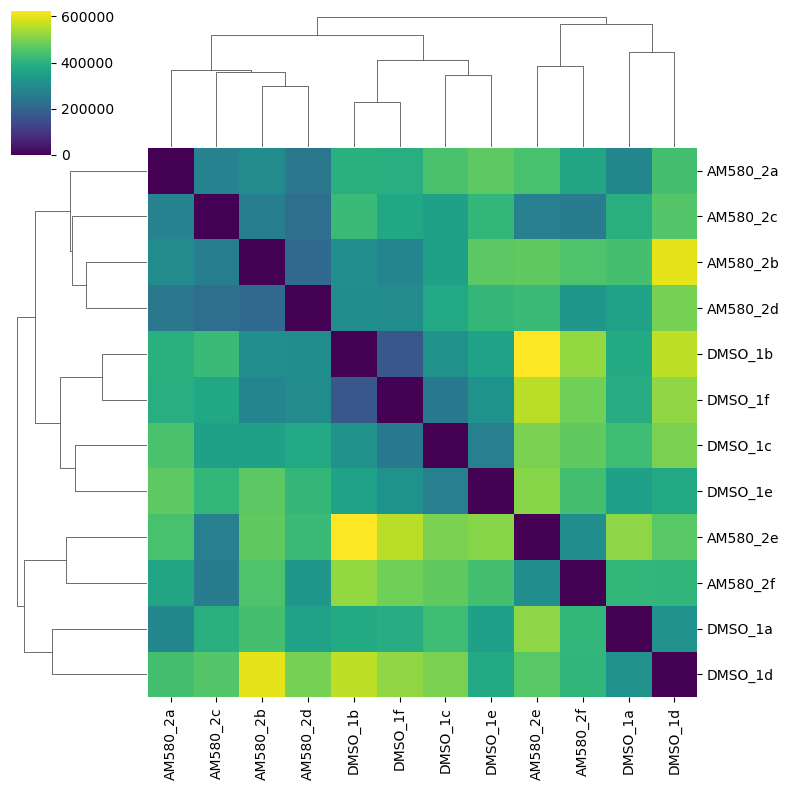

In [6]:
# generate heatmap of euclidean distances

sns.clustermap(
    dists_df,
    cmap="viridis",
    method="average",
    z_score=None,
    standard_scale=None,
    figsize=(8, 8)
)

In [21]:
# log transform before PCA

# transpose to samples x genes again
X = np.log10(counts_m.to_numpy() + 1.0).T
sample_names = counts_m.columns.tolist()

# scale features (genes) across samples
scaler = StandardScaler(with_mean=True, with_std=True)
X_scaled = scaler.fit_transform(X)

# this code will need to be updated by which character separates them
sample_ids = list(counts_m.columns)

# create a DataFrame with sample_id
metadata = pd.DataFrame({"sample_id": sample_ids})
metadata
parts = metadata["sample_id"].str.split("_", expand=True) # my samples are split by the same delimiter
parts = metadata["sample_id"].str.extract(
    r"^(?P<treatment>[^_]+)_(?P<bio_rep>\d+)(?P<tech_rep>[a-z]+)$"
)
parts

metadata = pd.concat([metadata, parts], axis=1)
metadata = metadata.set_index("sample_id")
metadata

,treatment,bio_rep,tech_rep
sample_id,,,
DMSO_1a,DMSO,1,a
DMSO_1b,DMSO,1,b
DMSO_1c,DMSO,1,c
DMSO_1d,DMSO,1,d
DMSO_1e,DMSO,1,e
DMSO_1f,DMSO,1,f
AM580_2a,AM580,2,a
AM580_2b,AM580,2,b
AM580_2c,AM580,2,c


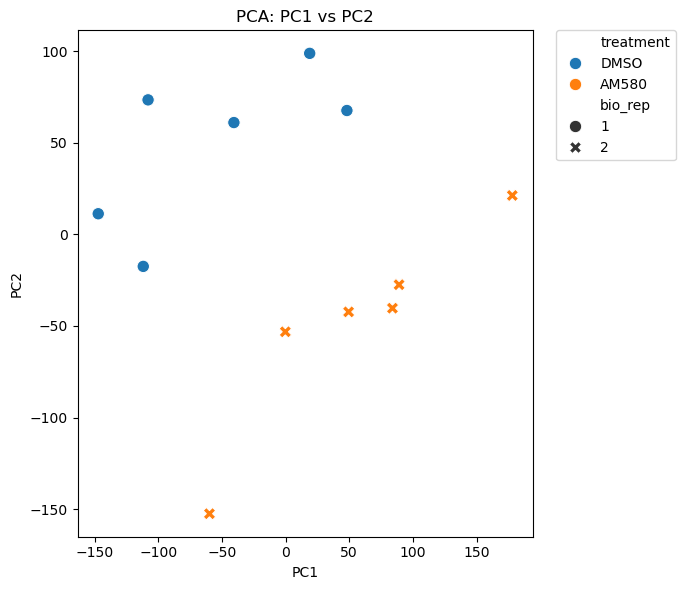

In [12]:
# do actual PCA now

pca = PCA(n_components=10, random_state=0)
scores = pca.fit_transform(X_scaled)
# explained = pca.explained_variance_ratio_

scores_df = pd.DataFrame(
    scores[:, :2],  # PC1 and PC2 for plotting
    index=sample_names,
    columns=["PC1", "PC2"]
)

plot_df = scores_df.join(metadata[["treatment", "bio_rep"]], how="left")

# plot
plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="treatment",     # color by treatment
    style="bio_rep",     # shape bi bio_rep
    s=80
)
plt.title("PCA: PC1 vs PC2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0.)
plt.tight_layout()
plt.show() 
# the plot has one obvious outlier in the bottom left. Overall, ther is just not much clustering at all.

## Perform differential expression

Use Python and DESeq2 to perform differential expression analysis on your counts. Generate a volcano plot of the data.

In [15]:
set(metadata.index) == set(counts_m.columns) # check that the metadata matches

inference = DefaultInference(n_cpus=32)

dds = DeseqDataSet(
    counts=counts_m.T,        # genes x samples, integer counts, transposed
    metadata=metadata,         # DataFrame indexed by sample_id
    design_factors="treatment",  # single factor name present in metadata
    refit_cooks=True,
    inference=inference
)

dds.deseq2()
dds


Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 2.10 seconds.

Fitting dispersion trend curve...
... done in 0.73 seconds.

Fitting MAP dispersions...
... done in 1.67 seconds.

Fitting LFCs...
... done in 1.95 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.



AnnData object with n_obs × n_vars = 12 × 30886
    obs: 'treatment', 'bio_rep', 'tech_rep'
    uns: 'trend_coeffs', 'disp_function_type', '_squared_logres', 'prior_disp_var'
    obsm: 'design_matrix', 'size_factors', '_mu_LFC', '_hat_diagonals', 'replaceable'
    varm: '_normed_means', 'non_zero', '_MoM_dispersions', 'genewise_dispersions', '_genewise_converged', 'fitted_dispersions', 'MAP_dispersions', '_MAP_converged', 'dispersions', '_outlier_genes', 'LFC', '_LFC_converged', 'replaced', 'refitted'
    layers: 'normed_counts', '_mu_hat', 'cooks'

In [23]:
# fit model to transformed data
dds.varm["LFC"]

# calculate adjusted p values - padj
stat_res = DeseqStats(dds, inference=inference)
stat_res.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: treatment DMSO vs AM580
                       baseMean  log2FoldChange     lfcSE      stat    pvalue  \
AMEX60DD000002        57.566609       -0.287236  0.203930 -1.408503  0.158982   
AMEX60DD000003       506.686389       -0.063069  0.104313 -0.604616  0.545434   
AMEX60DD000004       123.203547       -0.182803  0.148627 -1.229944  0.218718   
AMEX60DD000005        93.963686       -0.227203  0.177293 -1.281510  0.200014   
AMEX60DD000006       268.809746        0.003087  0.128479  0.024027  0.980831   
...                         ...             ...       ...       ...       ...   
AMEX60DDU001042227  1074.791895        4.719758  1.094680  4.311540       NaN   
AMEX60DDU001042231     2.143143        1.297194  1.069819  1.212536  0.225307   
AMEX60DDU001042244     1.802442       -0.359918  0.942443 -0.381899  0.702536   
AMEX60DDU001042245    15.638688       -0.312422  1.067903 -0.292556  0.769861   
AMEX60DDU001042261     3.944259        1.029671

... done in 6.73 seconds.



Choose one gene from the paper that was highlighted as being differentially expressed. Compare your data for this gene (raw counts if available, log<sub>2</sub> fold-change, and adjusted p-values) to the data reported in the paper.

Re-generate the PCA plot, now on counts that have had the variance-stabilizing tranformation performed on them.

Fit type used for VST : parametric


Fitting dispersions...
... done in 1.71 seconds.



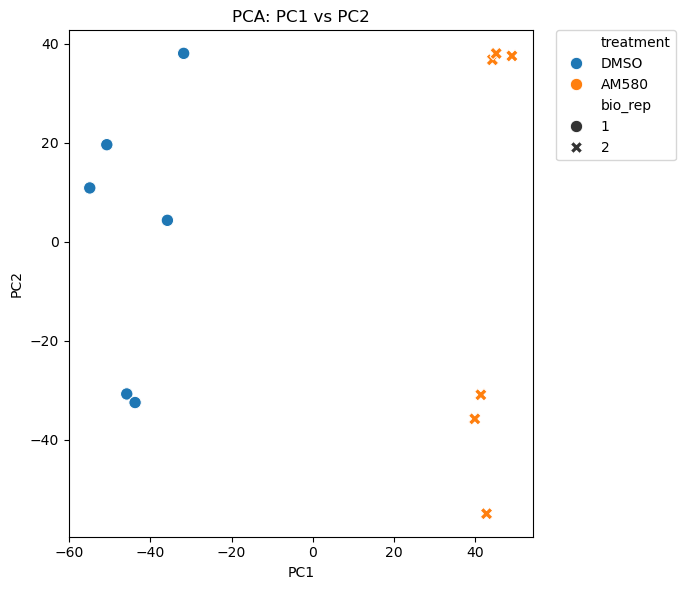

In [25]:
# redo PCA

dds.vst() 
X = dds.layers["vst_counts"]   # shape: (samples, genes)
obs = dds.obs  # sample metadata DataFrame

pca = PCA(n_components=10, random_state=0)
scores = pca.fit_transform(X)
# explained = pca.explained_variance_ratio_

scores_df = pd.DataFrame(
    scores[:, :2],  # PC1 and PC2 for plotting
    index=sample_names,
    columns=["PC1", "PC2"]
)

plot_df = scores_df.join(metadata[["treatment", "bio_rep"]], how="left")

# plot
plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="treatment",     # color by tissue
    style="bio_rep",
    s=80
)
plt.title("PCA: PC1 vs PC2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0.)
plt.tight_layout()
plt.show()

## Snakemake Pipeline (optional)

1. Copy your `Snakefile` and `config.yaml` from `8_counting` to `9_differential_expression`.  
2. In the `Snakefile`, add the following rules:  
    a. `differential_expression` - write a Python script that performs QC (clustering and PCA) and differential expression. The rule should run the script, and the output should be plots (heatmap, PCA, volcano plot) and a CSV of the DEGs.

This `Snakefile` should not use any `wrappers` because we already have the relevant software installed in the `biol343` conda environment. The pipeline should run to completion when any instructor or classmate runs `snakemake --use-conda`.